In [1]:
# Project paths: run Jupyter from this repository or a notebook subdirectory.
# Saved outputs are from the original archive; they have not been recomputed.
from pathlib import Path
import os

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data" / "random_numbers.npz").is_file()), None
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter inside the monsoon_bias_MAP24 repository.")
DATA_DIR = Path(os.environ.get("PRECIP_DATA_DIR", str(PROJECT_ROOT / "data"))).expanduser()
WEIGHTS_DIR = Path(os.environ.get("PRECIP_WEIGHTS_DIR", str(PROJECT_ROOT / "models"))).expanduser()
RESULTS_DIR = PROJECT_ROOT / "results"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import h5py
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, GlobalAveragePooling1D, LSTM, Dense
from tensorflow.keras.layers import Dropout, Input, Add,  Conv2DTranspose, Reshape
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
import matplotlib.pyplot as plt
import os
import random
import xarray as xr
import pickle
from sklearn.preprocessing import StandardScaler
import dask
import dask.dataframe as dd
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras import layers, models
from dask.distributed import Client
client = Client()

In [2]:
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

In [3]:
data=np.load(str(DATA_DIR / "ml_data_pr.npz"))
X0=data['X']
Y=data['Y']

# GEOS-S2S-3 VP data for forecast month
data1=np.load(str(DATA_DIR / "ml_data1.npz"))
X1=data1['X1']
X1[np.isnan(X1)]=np.nanmean(X1)

# M2 VP data for forecast month 
data2=np.load(str(DATA_DIR / "ml_data2.npz"))
X2=data2['X1']
X2[np.isnan(X2)]=np.nanmean(X2)

nx=len(data['lon'])
ny=len(data['lat'])

lon1=(data1['lon1'])
lat1=(data1['lat1'])

lon=(data['lon'])
lat=(data['lat'])
date=(data['date'])

In [4]:
# fig=plt.figure(figsize=(11.5,8))
# clf=np.arange(-4,4.1,1)*1e6
# plot((X1-X2)[0,:,:,0],lon1,lat1,clf=clf,cmap=cmap,sub=[1,1,1],fig=fig,)


In [5]:
# X1=X1-X2

In [6]:
x0mean = X0.mean()
x0std = X0.std()

# Normalize the data
normalized_X0 = (X0 - x0mean) / x0std

In [7]:
x1mean = X1.mean()
x1std = X1.std()

# Normalize the data
normalized_X1 = (X1 - x1mean) / x1std

In [8]:
x2mean = X2.mean()
x2std = X2.std()

# Normalize the data
normalized_X2 = (X2 - x2mean) / x2std

In [9]:
normalized_X=np.concatenate((normalized_X0,normalized_X1, normalized_X2 ),axis=3)

# normalized_X=np.concatenate((X0,X1),axis=3)
# normalized_Y=Y

In [10]:
ymean = Y.mean()
ystd = Y.std()

# Normalize the data
normalized_Y = (Y - ymean) / ystd


In [11]:
# import random
# random_numbers = random.sample(range(0, (len(X))),len(X))

In [12]:
#np.savez(str(PROJECT_ROOT / "data" / "random_numbers.npz"),random_numbers=random_numbers)
random_numbers=np.load(str(PROJECT_ROOT / "data" / "random_numbers.npz"))['random_numbers']

In [13]:
normalized_X=normalized_X[random_numbers,:,:,:]
normalized_Y=normalized_Y[random_numbers,:,:,:]
date=date[random_numbers]

In [14]:
# normalized_Y=Y
# normalized_X=X

In [15]:
nf = 7  # number of input features
nv = 2  # number of variables to be forecasted
nx = 101  # spatial dimension width
ny = 91   # spatial dimension height

# Define the input shape
input_shape = (ny, nx, nf)

model = models.Sequential()

# First convolutional layer with 32 filters, 3x3 kernel size
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape))
model.add(layers.BatchNormalization())  # Helps in normalizing the activations and gradients

# Second convolutional layer with 64 filters, 3x3 kernel size
model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Additional convolutional layer with 128 filters
model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Additional convolutional layer with 128 filters
model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Final layer to produce the output with `nv` channels
model.add(layers.Conv2D(nv, (1, 1), activation='linear', padding='same'))

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Display the model summary
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 91, 101, 32)       2048      
_________________________________________________________________
batch_normalization (BatchNo (None, 91, 101, 32)       128       
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 91, 101, 64)       18496     
_________________________________________________________________
batch_normalization_1 (Batch (None, 91, 101, 64)       256       
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 91, 101, 128)      73856     
_________________________________________________________________
batch_normalization_2 (Batch (None, 91, 101, 128)      512       
_________________________________________________________________
conv2d_3 (Conv2D)            (None, 91, 101, 256)      2

In [16]:
X_norm_train=normalized_X[0:500,:,:,:]
Y_norm_train=normalized_Y[0:500,:,:,:]

In [17]:
X_norm_test=normalized_X[500:,:,:,:]
Y_norm_test=normalized_Y[500:,:,:,:]

In [18]:
model_weights_path = str(WEIGHTS_DIR / "best_model_weights2.h5")

In [19]:

try:
    model.load_weights(model_weights_path)
    print("Loaded weights from previous model!")
except:
    print("No previous weights found, starting from scratch.")

Loaded weights from previous model!


In [20]:

    

# checkpoint = ModelCheckpoint(model_weights_path, save_best_only=True, save_weights_only=True, monitor='val_loss', mode='min',verbose=1)

# history = model.fit(X_norm_train, Y_norm_train, epochs=100, batch_size=100, validation_split=.1, callbacks=[checkpoint])

In [21]:
# train_loss = history.history['loss']
# val_loss = history.history['val_loss']

# # Plotting the training and validation loss
# plt.figure(figsize=(10, 5))
# plt.plot(train_loss, label='Training Loss')
# plt.plot(val_loss, label='Validation Loss')
# plt.title('Training vs Validation Loss')
# plt.xlabel('Epochs')
# plt.ylabel('Loss')
# plt.legend()
# plt.show()

In [22]:
# load best model

model.load_weights(str(WEIGHTS_DIR / "best_model_weights2.h5"))

In [23]:
#testing

#Test

Yp_norm_test = model.predict(X_norm_test)

In [24]:
# 1. Load the saved scaler for Y from the pickle file
# 4. Reshape back to original 5D shape
original_Yp = Yp_norm_test * ystd + ymean
original_Y = Y_norm_test * ystd + ymean

original_X = X_norm_test * x0std + x0mean

In [25]:
# # 1. Load the saved scaler for Y from the pickle file
# # 4. Reshape back to original 5D shape
# original_Yp = Yp_norm_test# * ystd + ymean
# original_Y = Y_norm_test #* ystd + ymean

# original_X = X_norm_test# * xstd + xmean

In [26]:
rmse=np.sqrt(np.mean((original_Yp[:,:,:,1]-original_Y[:,:,:,1])**2,0))
rmse2=np.sqrt(np.mean((original_X[:,:,:,2]-original_Y[:,:,:,1])**2,0))

In [27]:
original_Yp[:,:,:,1].shape

(40, 91, 101)

In [28]:
corr=np.zeros(rmse.shape)
corr2=np.zeros(rmse.shape)

for i in range(91):
    for j in range(101):
        corr[i,j]=np.corrcoef(original_Yp[:,:,:,1][:,i,j],original_Y[:,:,:,1][:,i,j])[0,1]
        corr2[i,j]=np.corrcoef(original_X[:,:,:,2][:,i,j],original_Y[:,:,:,1][:,i,j])[0,1]

In [29]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

#fig = plt.figure(figsize=(11, 8.5))

# Create an axes with the PlateCarree projection

def plot(data,lon,lat,cmap='coolwarm',fig=[],nx=[],ny=[],sub=[1,1,1],clf=[],frac=.045):

    ax = fig.add_subplot(sub[0], sub[1], sub[2], projection=ccrs.PlateCarree())

    # Example usage of the axes
    ax.coastlines()  # Adds coastlines
    try:
        ax.set_extent([nx[0], nx[1], ny[0], ny[1]]) # define the boundary
    except:
        None

    try:
        cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both',levels=clf)
    except:
                cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both')

    plt.colorbar(cc,orientation='horizontal',  shrink=5,pad=0.1,fraction=frac)
    gl = ax.gridlines(draw_labels=True, linewidth=0.01)

    gl.xlabels_top = False  # Disable labels on the top
    gl.ylabels_right = False  # Disable labels on the right
    gl.xformatter = ccrs.cartopy.mpl.gridliner.LONGITUDE_FORMATTER
    gl.yformatter = ccrs.cartopy.mpl.gridliner.LATITUDE_FORMATTER

    return(ax)
#map5.contourf(lon,lat,Yp_norm_test[nn,:,:,1])


2


/panfs/ccds02/app/modules/anaconda/platform/x86_64/rhel/8.6/3-2022.05/envs/earthml/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:307: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/panfs/ccds02/app/modules/anaconda/platform/x86_64/rhel/8.6/3-2022.05/envs/earthml/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:343: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


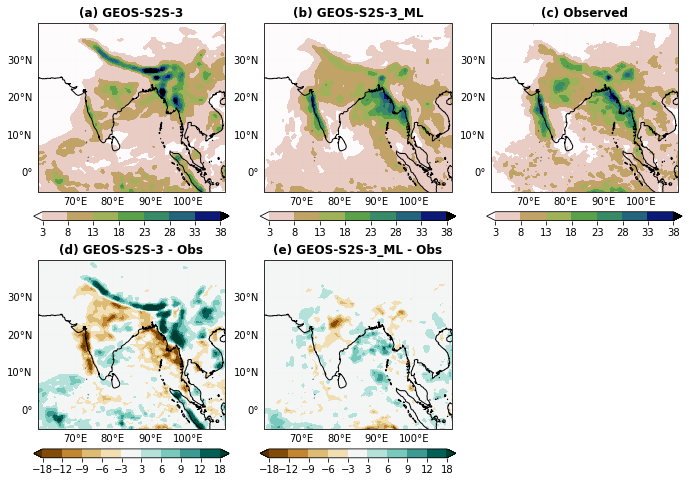

In [30]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)


In [31]:
date[500+nn]

numpy.datetime64('2016-05-26T00:00:00.000000000')

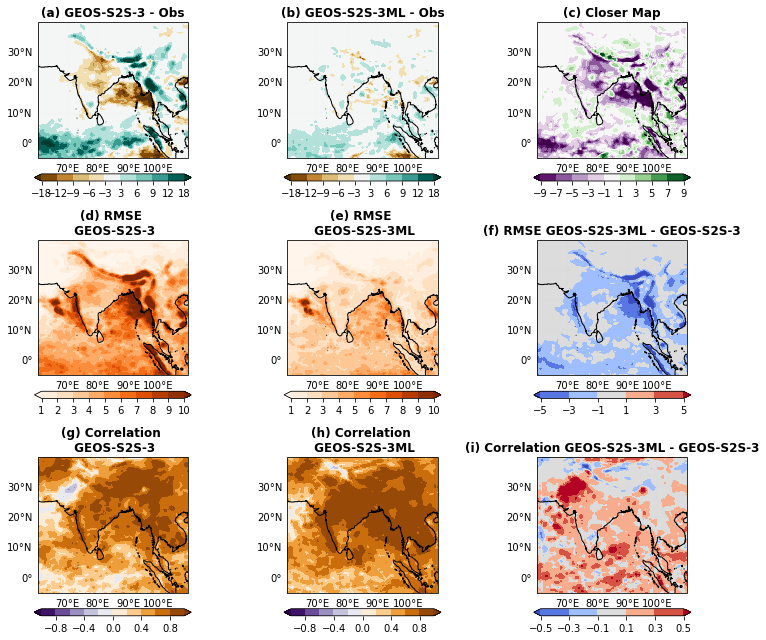

In [32]:
fig=plt.figure(figsize=(11,9))
clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
cmap='BrBG'
i=2
nn=14
plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[3,3,1],fig=fig)
plt.title('(a) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[3,3,2],fig=fig)
plt.title('(b) GEOS-S2S-3ML - Obs',fontweight='bold', fontsize=12)

clf=np.arange(-9,9.1,2)

dif1=original_X[nn,:,:,l+1]-original_Y[nn,:,:,l]
dif2=(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l])

diff=(abs(dif2)-abs(dif1))#*100/abs(dif2)
# diff[diff>50]=0
# diff[diff<-100]=0
cmap='PRGn'
plot(diff,lon,lat,cmap=cmap,clf=clf,sub=[3,3,3],fig=fig)
plt.title('(c) Closer Map',fontweight='bold', fontsize=12)


clf=np.arange(1,11,1)
cmap='Oranges'
plot(rmse,lon,lat,cmap=cmap,sub=[3,3,2+3],clf=clf,fig=fig)
plt.title('(e) RMSE \n GEOS-S2S-3ML', fontweight='bold')
plot(rmse2,lon,lat,cmap=cmap,sub=[3,3,1+3],clf=clf,fig=fig)
plt.title('(d) RMSE \n GEOS-S2S-3', fontweight='bold')

clf=np.arange(-.5,.51,.2)*10
cmap='coolwarm'
plot(rmse-rmse2,lon,lat,cmap=cmap,sub=[3,3,3+3],clf=clf,fig=fig)
plt.title('(f) RMSE GEOS-S2S-3ML - GEOS-S2S-3', fontweight='bold')

clf=np.arange(-1,1.1,.2)
cmap='PuOr_r'
plot(corr,lon,lat,cmap=cmap,sub=[3,3,5+3],clf=clf,fig=fig)
plt.title('(h) Correlation \n GEOS-S2S-3ML', fontweight='bold')
plot(corr2,lon,lat,cmap=cmap,sub=[3,3,4+3],clf=clf,fig=fig)
plt.title('(g) Correlation \n GEOS-S2S-3', fontweight='bold')

clf=np.array([-.5,-.3,-.1,.1,.3,.5])
cmap='coolwarm'
plot(corr-corr2,lon,lat,cmap=cmap,sub=[3,3,6+3],clf=clf,fig=fig)
plt.title('(i) Correlation GEOS-S2S-3ML - GEOS-S2S-3', fontweight='bold')
plt.tight_layout()
plt.savefig(str(RESULTS_DIR / "gmao.png"),dpi=200)



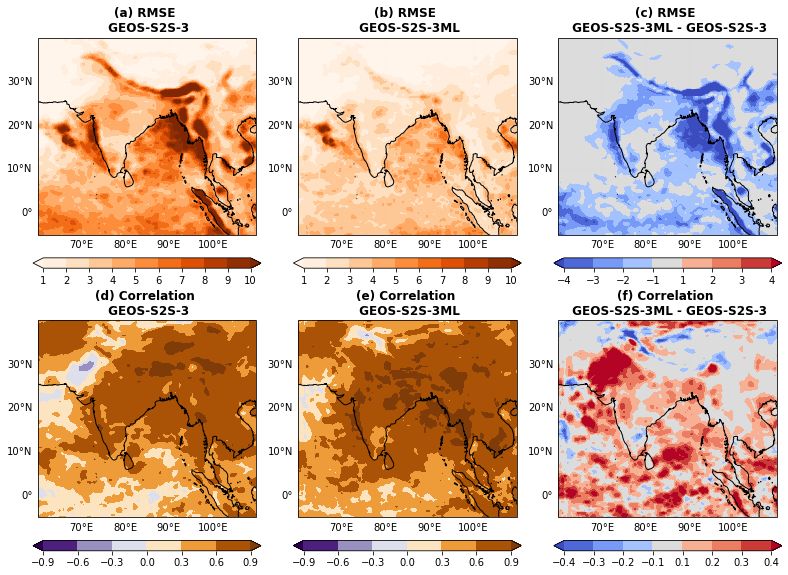

In [33]:
fig=plt.figure(figsize=(11,8))


clf=np.arange(1,11,1)
cmap='Oranges'
plot(rmse,lon,lat,cmap=cmap,sub=[2,3,2],clf=clf,fig=fig)


plt.title('(b) RMSE \n GEOS-S2S-3ML', fontweight='bold')
plot(rmse2,lon,lat,cmap=cmap,sub=[2,3,1],clf=clf,fig=fig)
plt.title('(a) RMSE \n GEOS-S2S-3', fontweight='bold')

clf=(np.array([-.4,-.3,-.2,-.1,.1,.2,.3,.4]))*10
cmap='coolwarm'
plot(rmse-rmse2,lon,lat,cmap=cmap,sub=[2,3,3],clf=clf,fig=fig)
plt.title('(c) RMSE \n GEOS-S2S-3ML - GEOS-S2S-3', fontweight='bold')

clf=np.arange(-.9,.91,.3)
cmap='PuOr_r'
plot(corr,lon,lat,cmap=cmap,sub=[2,3,5],clf=clf,fig=fig)
plt.title('(e) Correlation \n GEOS-S2S-3ML', fontweight='bold')
plot(corr2,lon,lat,cmap=cmap,sub=[2,3,4],clf=clf,fig=fig)
plt.title('(d) Correlation \n GEOS-S2S-3', fontweight='bold')

clf=np.array([-.4,-.3,-.2,-.1,.1,.2,.3,.4])
cmap='coolwarm'
plot(corr-corr2,lon,lat,cmap=cmap,sub=[2,3,6],clf=clf,fig=fig)
plt.title('(f) Correlation \n GEOS-S2S-3ML - GEOS-S2S-3', fontweight='bold')
plt.tight_layout()
plt.savefig(str(RESULTS_DIR / "gmao.png"),dpi=200)



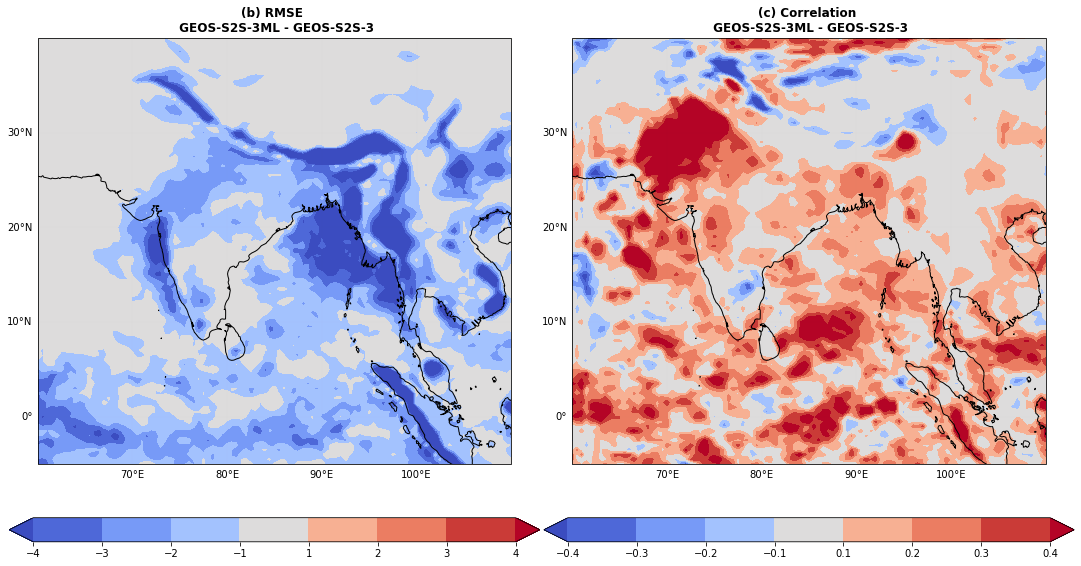

In [52]:
fig=plt.figure(figsize=(15,8))

clf=np.arange(1,11,1)

clf=(np.array([-.4,-.3,-.2,-.1,.1,.2,.3,.4]))*10
cmap='coolwarm'
plot(rmse-rmse2,lon,lat,cmap=cmap,sub=[1,2,1],clf=clf,fig=fig)
#plt.contour(lon,lat,rmse,levels=clf,colors='black')
plt.title('(b) RMSE \n GEOS-S2S-3ML - GEOS-S2S-3', fontsize=12,fontweight='bold')


clf=np.array([-.4,-.3,-.2,-.1,.1,.2,.3,.4])
cmap='coolwarm'

plot(corr-corr2,lon,lat,cmap=cmap,sub=[1,2,2],clf=clf,fig=fig)
#plt.contour(lon,lat,corr,levels=np.arange(0,1,.5),colors='black')

plt.title('(c) Correlation \n GEOS-S2S-3ML - GEOS-S2S-3', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(str(RESULTS_DIR / "gmao.png"),dpi=200)



Text(0.5, 0.98, '1 months lead mean')

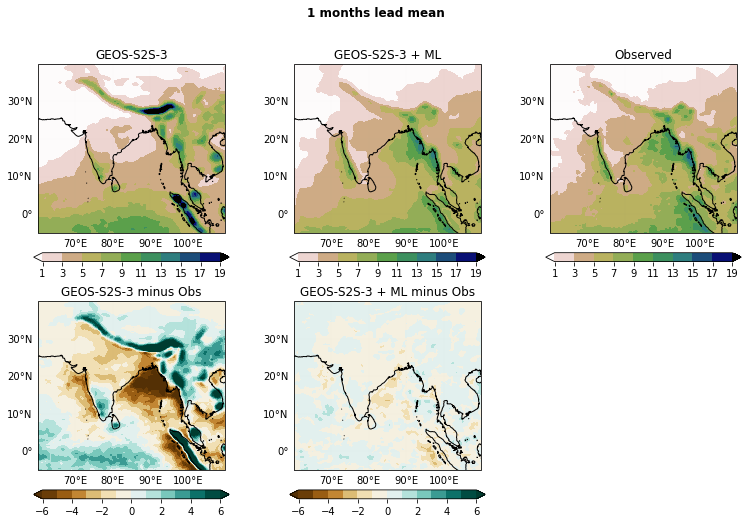

In [34]:
clf=np.arange(1,21,2)
cmap='gist_earth_r'

nn=3
l=0
fig=plt.figure(figsize=(13,8))

plot(np.nanmean(original_X[:,:,:,l+1],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
plt.title('GEOS-S2S-3')

plot(np.nanmean(original_Yp[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
plt.title('GEOS-S2S-3 + ML')



plot(np.nanmean(original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
plt.title('Observed')

clf=np.arange(-6,6.1,1)
cmap='BrBG'


plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
plt.title('GEOS-S2S-3 + ML minus Obs')

plot(np.nanmean(original_X[:,:,:,l+1]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
plt.title('GEOS-S2S-3 minus Obs')
plt.suptitle(str(l+1)+' months lead mean',fontsize=12,fontweight='bold')


Text(0.5, 0.98, '2 months lead mean')

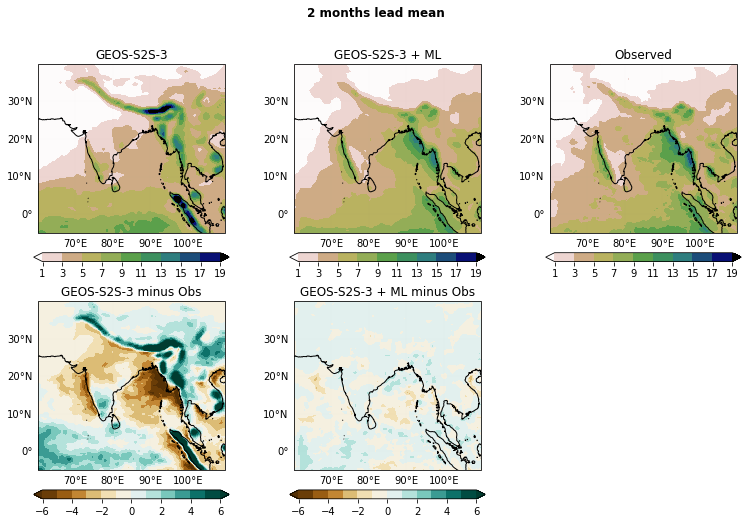

In [35]:
clf=np.arange(1,21,2)
cmap='gist_earth_r'

nn=34
l=1
fig=plt.figure(figsize=(13,8))

plot(np.nanmean(original_Yp[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
plt.title('GEOS-S2S-3 + ML')

plot(np.nanmean(original_X[:,:,:,l+1],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
plt.title('GEOS-S2S-3')

plot(np.nanmean(original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
plt.title('Observed')

clf=np.arange(-6,6.1,1)
cmap='BrBG'


plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
plt.title('GEOS-S2S-3 + ML minus Obs')

plot(np.nanmean(original_X[:,:,:,l+1]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
plt.title('GEOS-S2S-3 minus Obs')
plt.suptitle(str(l+1)+' months lead mean',fontsize=12,fontweight='bold')

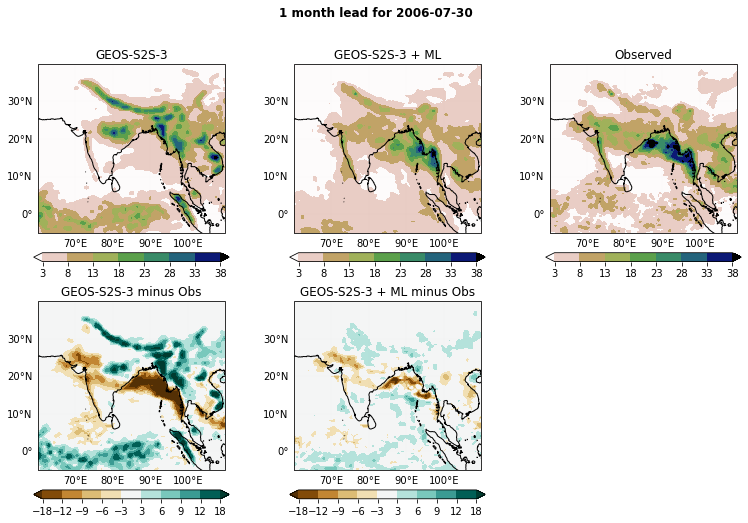

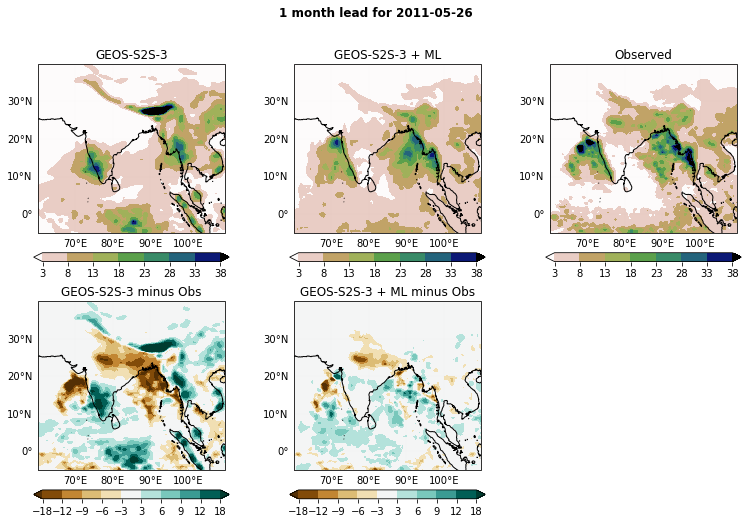

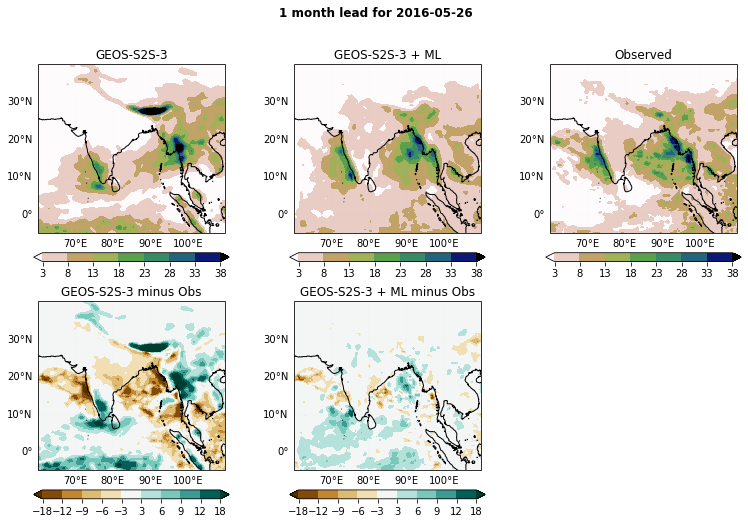

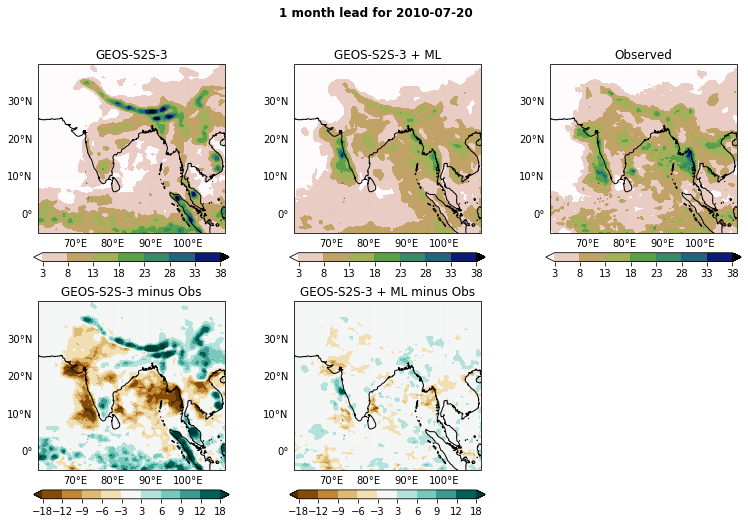

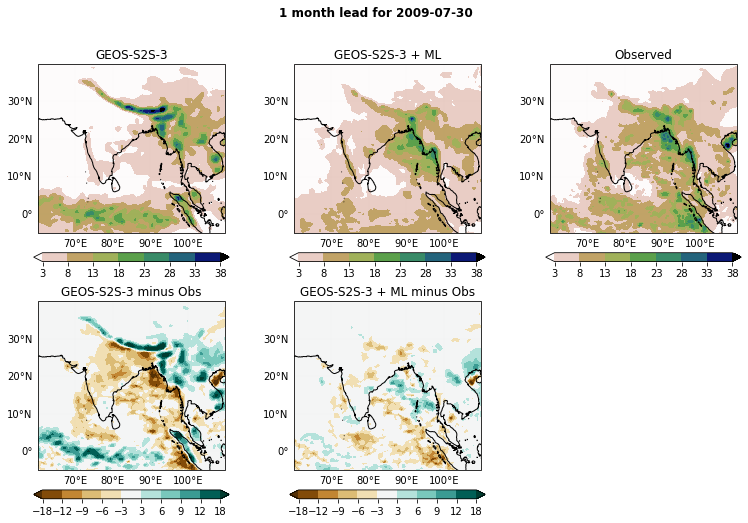

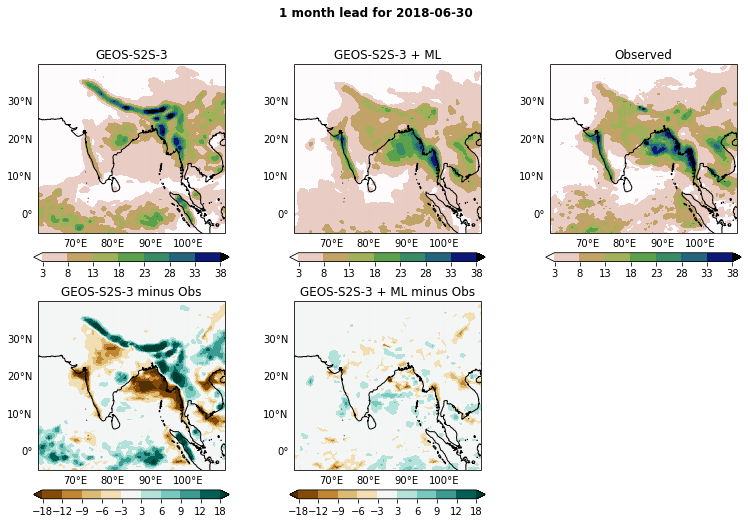

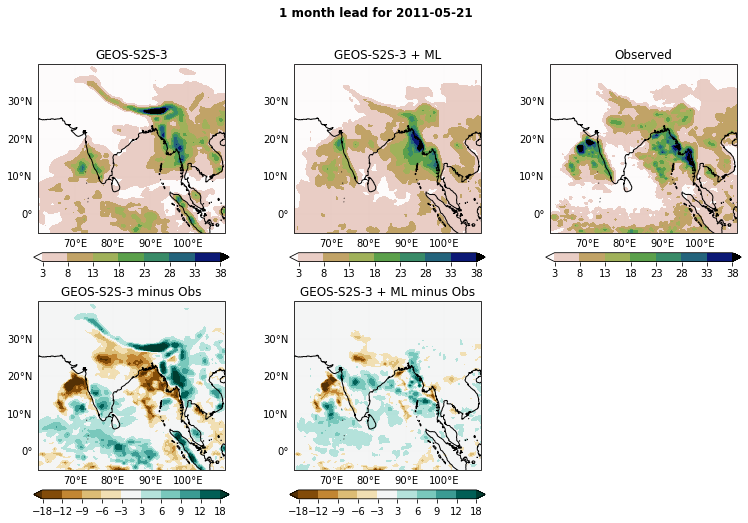

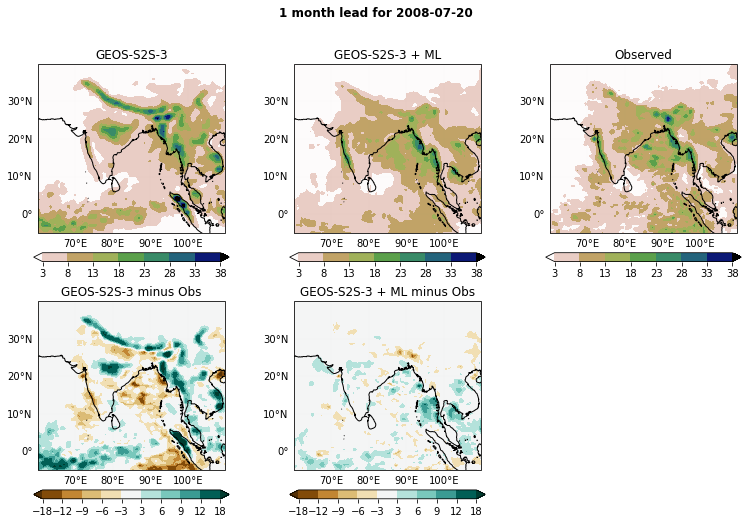

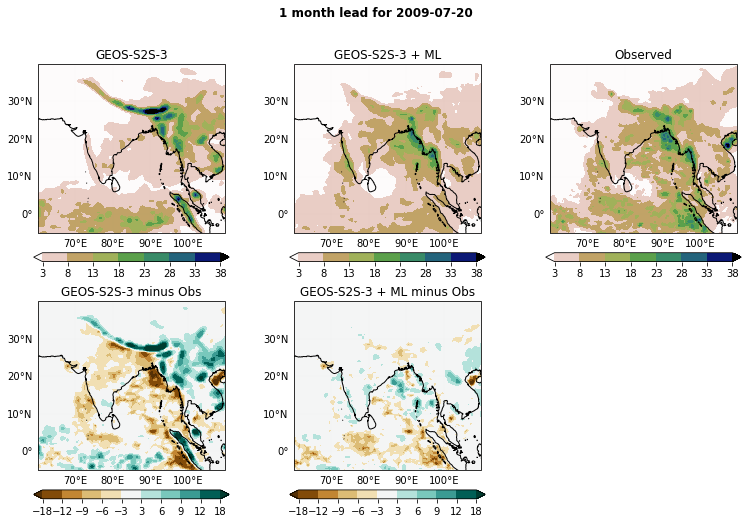

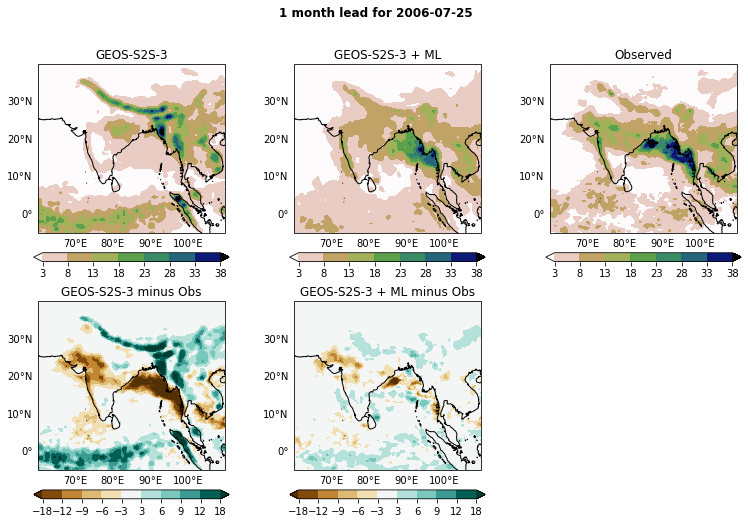

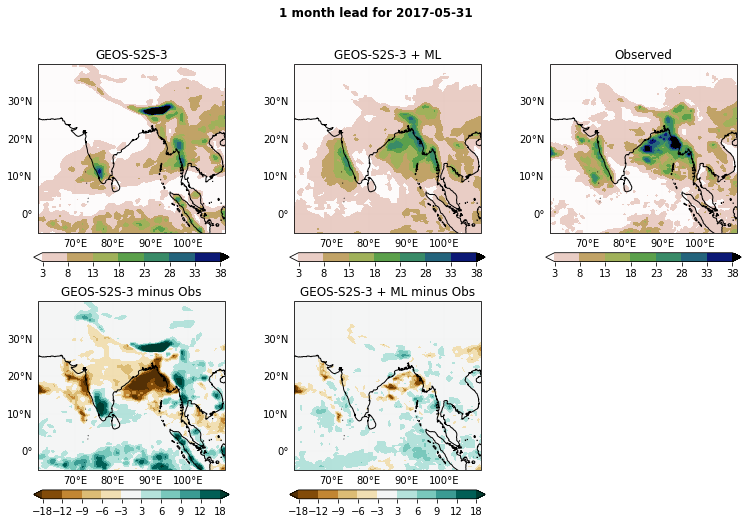

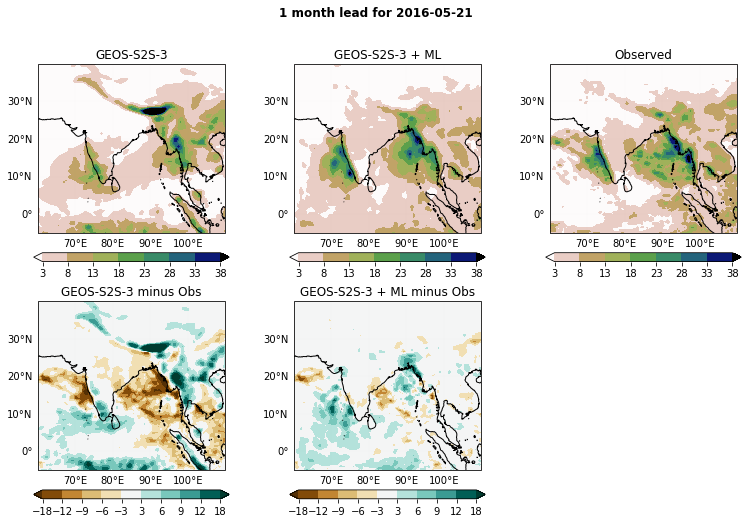

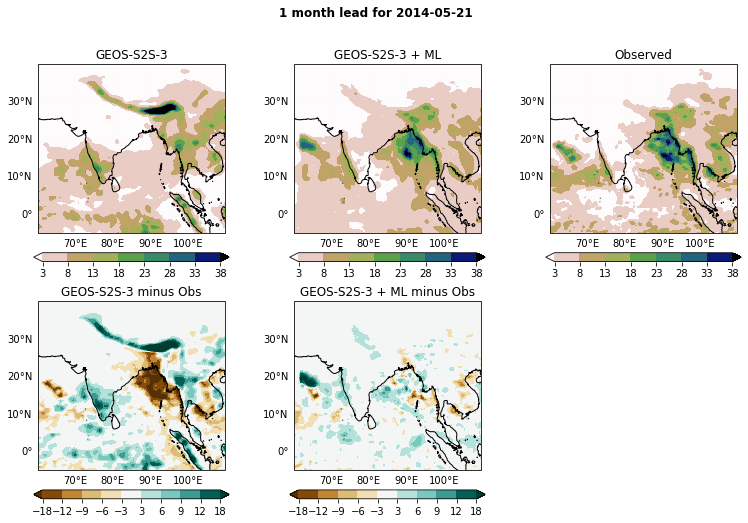

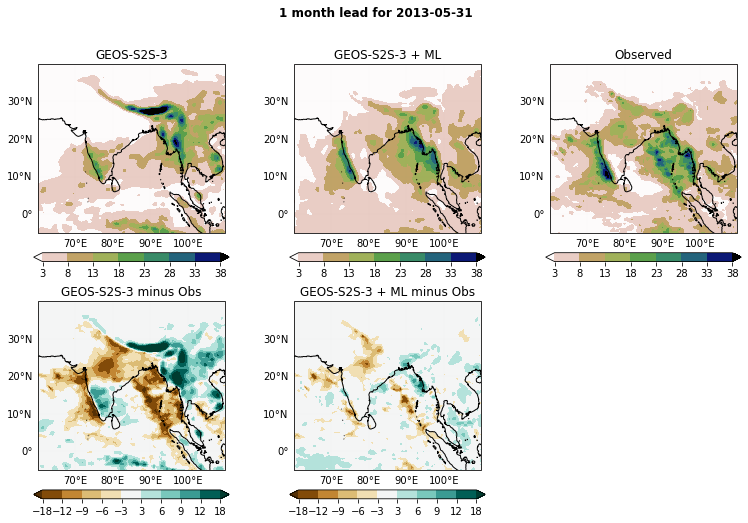

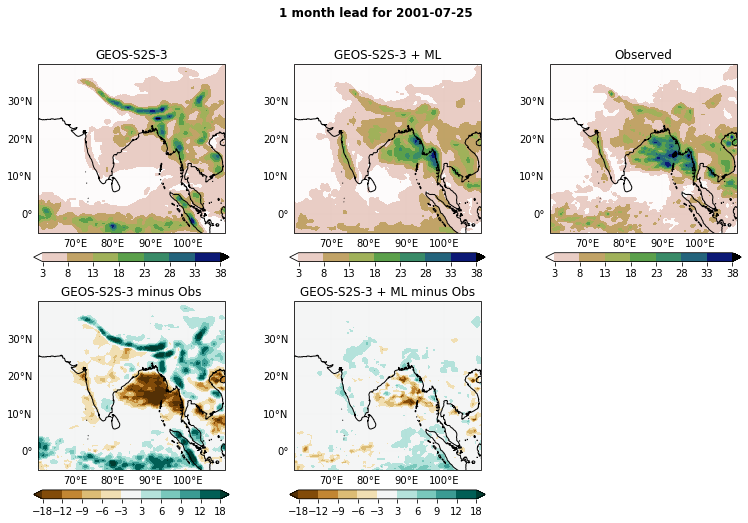

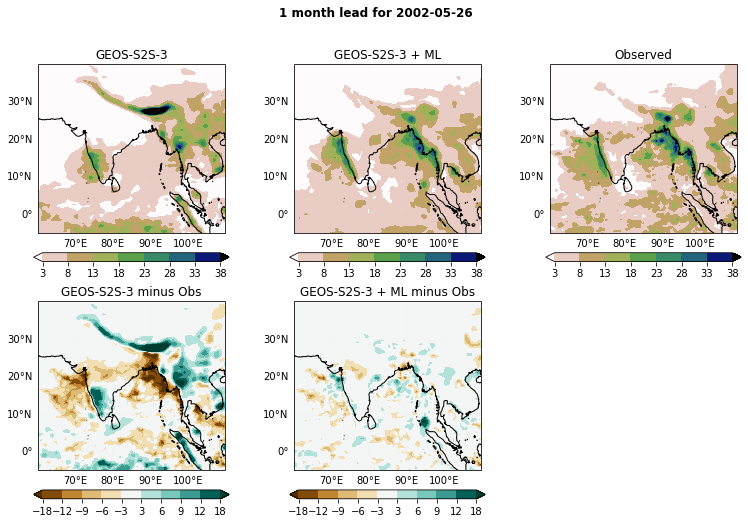

In [40]:
for i in range(39):
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):

        nn=i
        l=0
        fig=plt.figure(figsize=(13,8))
        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('GEOS-S2S-3')

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('Observed')

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('GEOS-S2S-3 + ML minus Obs')

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('GEOS-S2S-3 minus Obs')
        plt.suptitle(str(l+1)+' month lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
    else:
        None

0
1
2
7
9
14
18
22
23
28
29
32
34
35


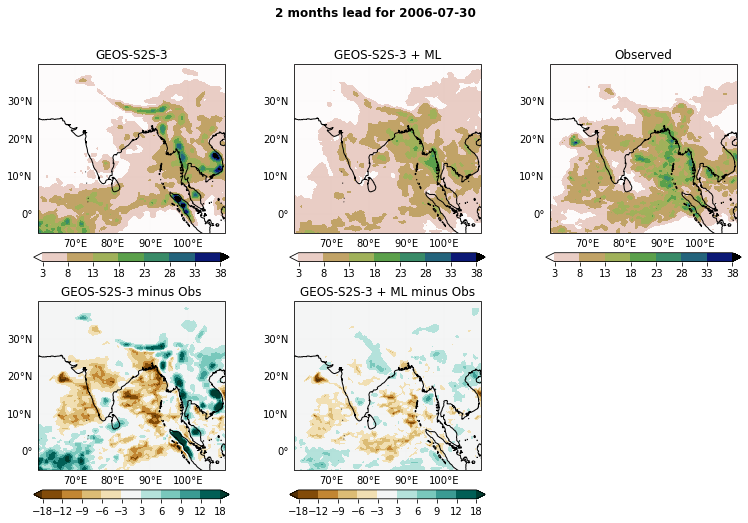

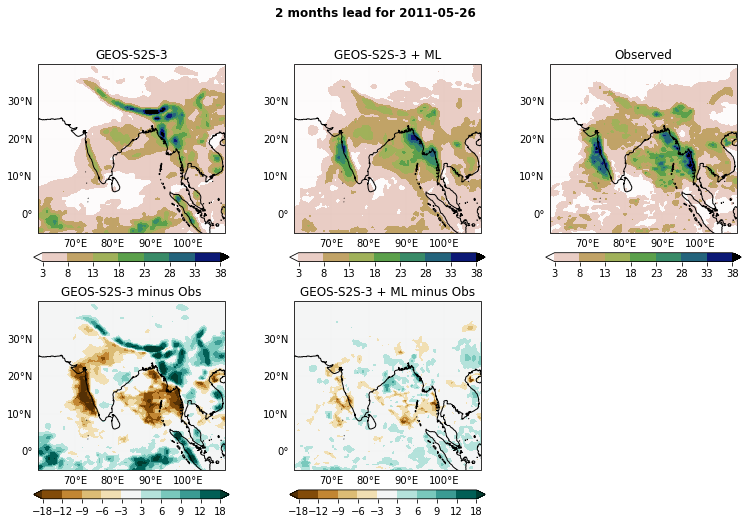

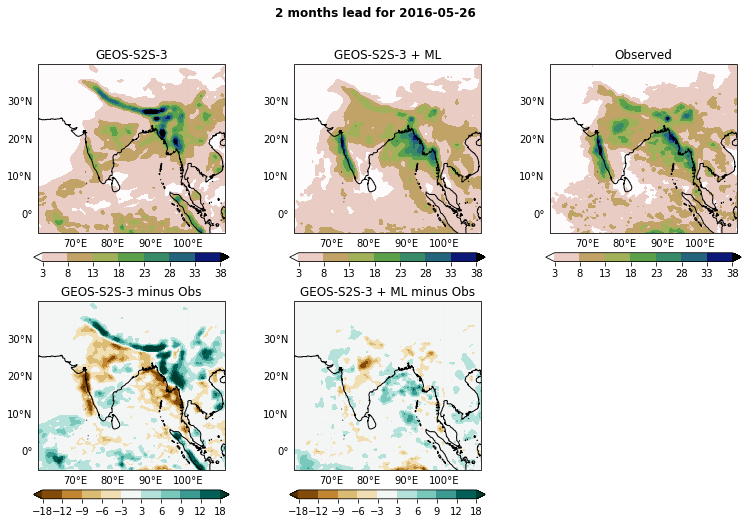

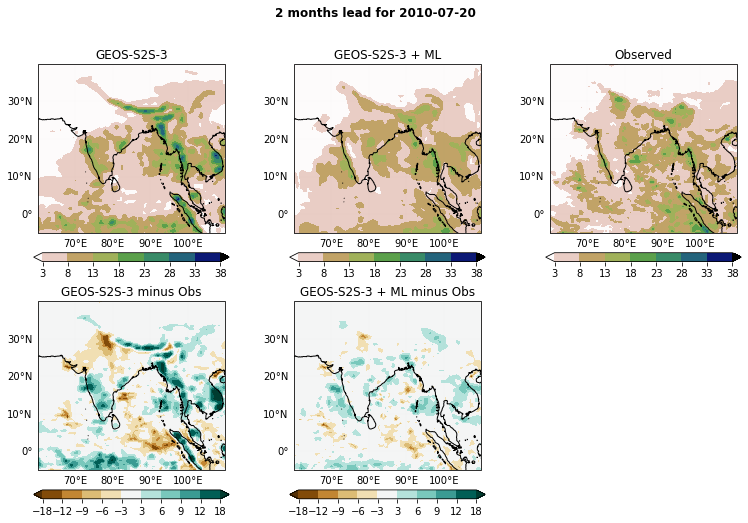

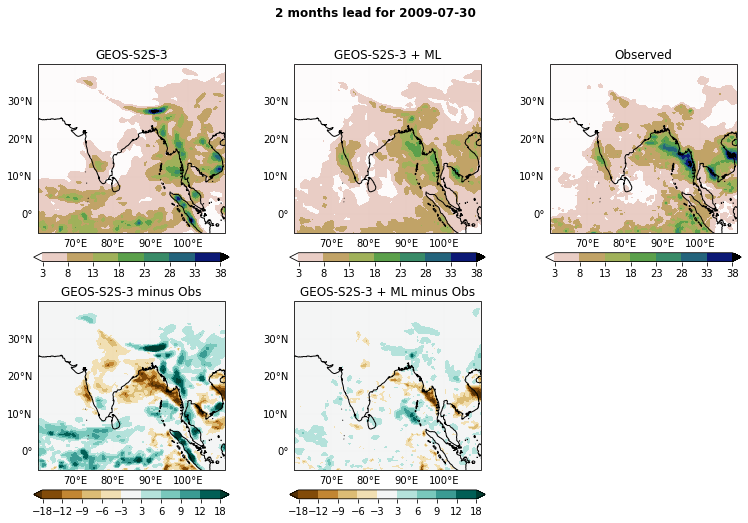

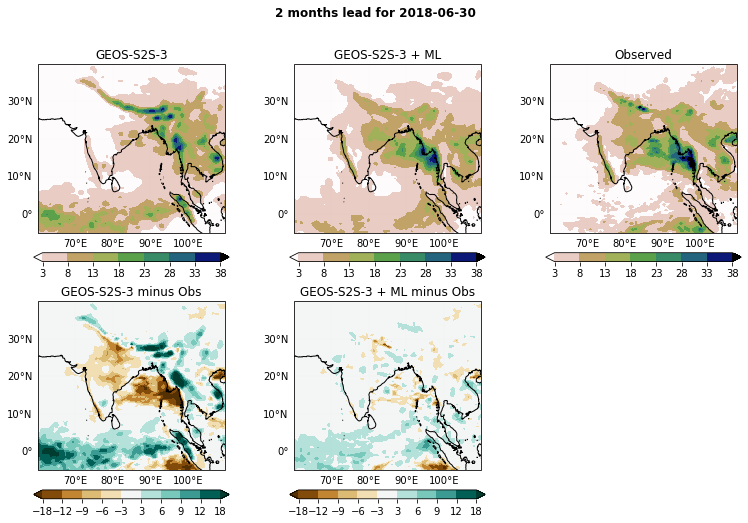

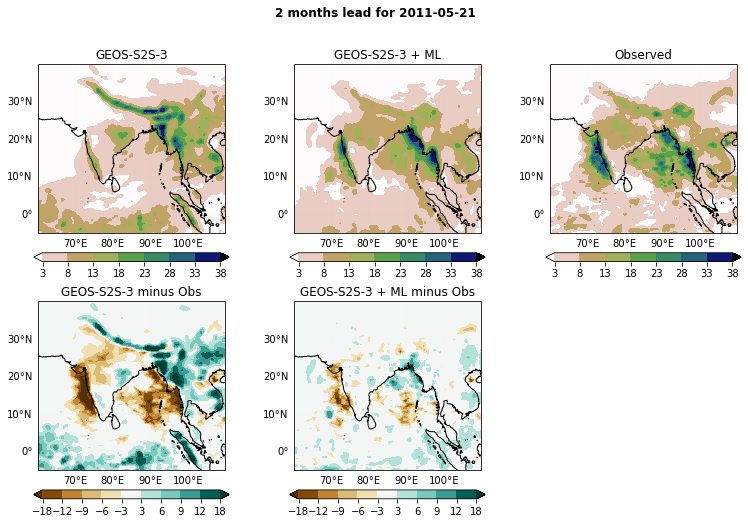

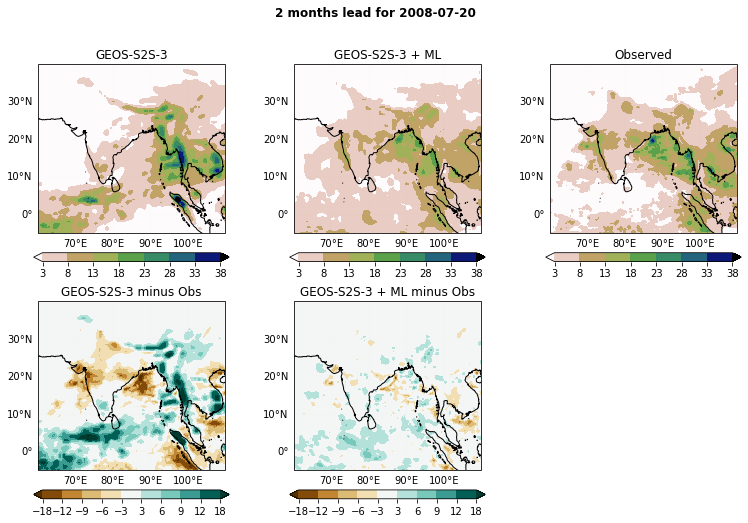

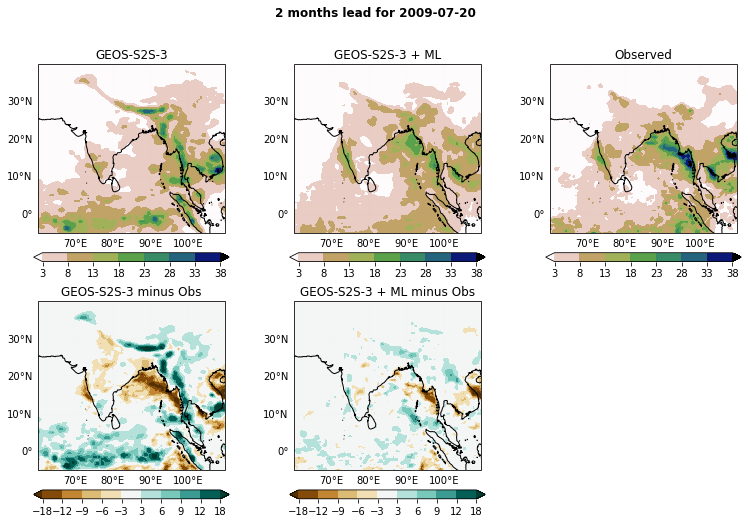

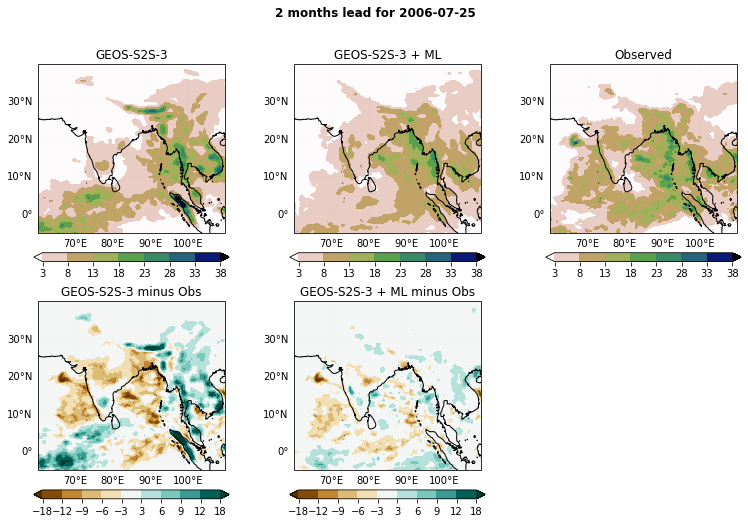

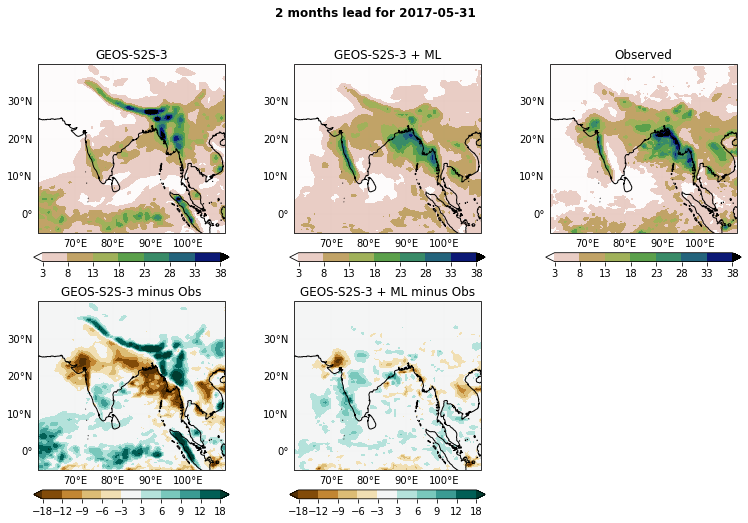

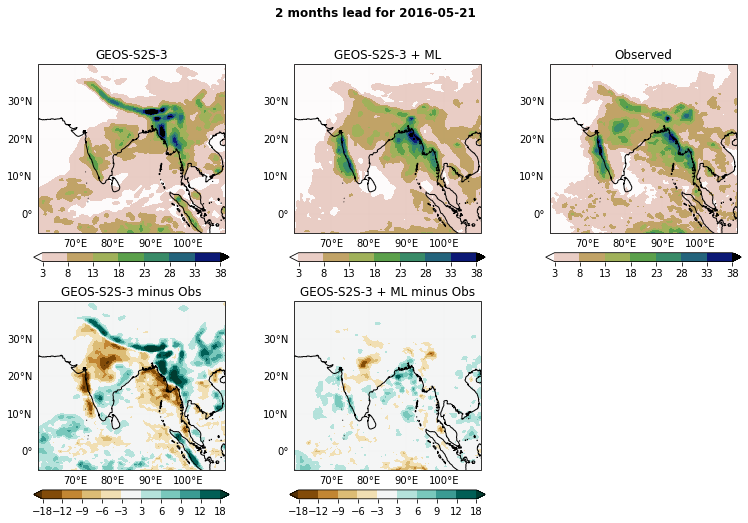

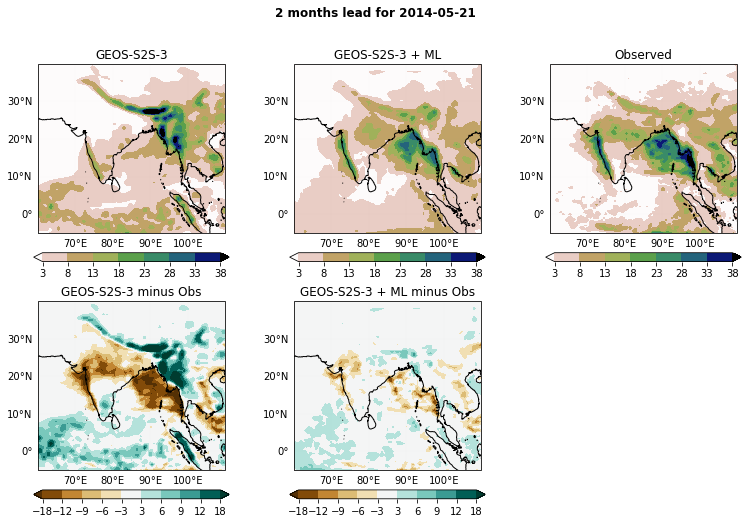

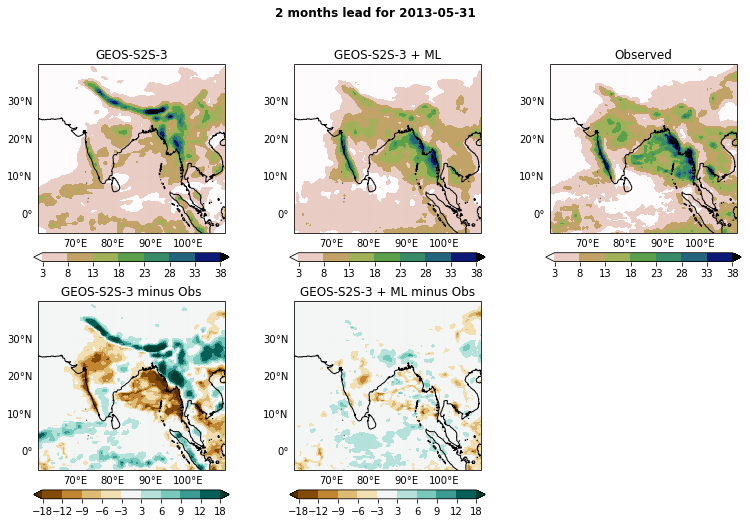

In [41]:


for i in range(36):
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(13,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('GEOS-S2S-3')

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('Observed')

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('GEOS-S2S-3 + ML minus Obs')

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('GEOS-S2S-3 minus Obs')
        plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')

2


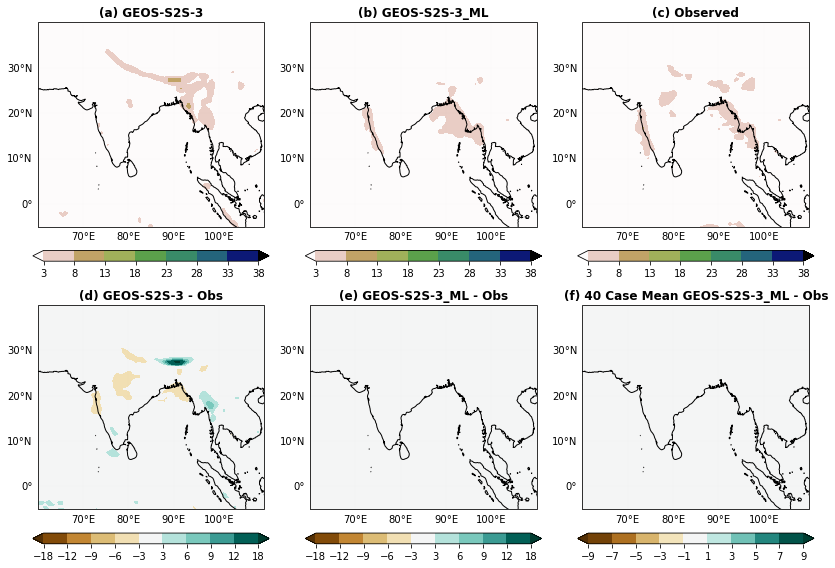

In [30]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

        plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=np.arange(-9,9.1,2),sub=[2,3,6],fig=fig)
        plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)
        
        plt.tight_layout()
        #plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
        #plt.savefig(str(RESULTS_DIR / "GEOSML.png"),dpi=200)

2


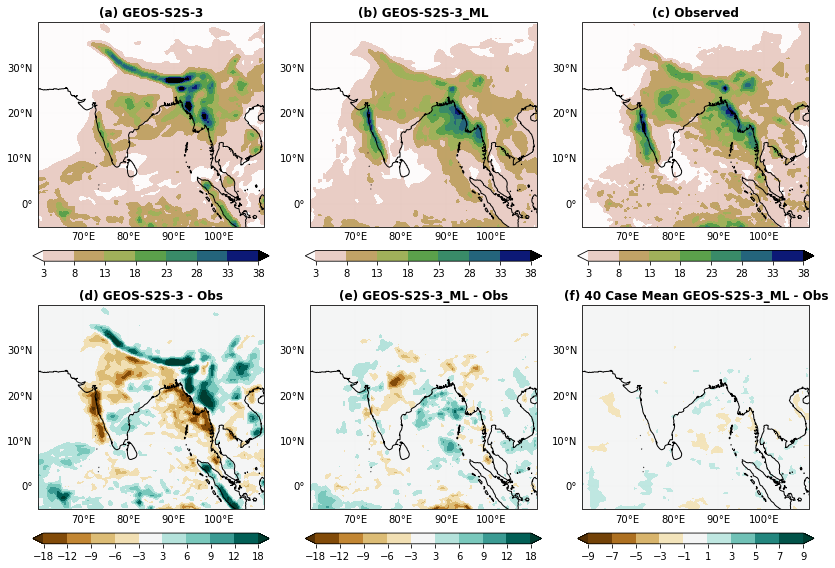

In [72]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

        plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=np.arange(-9,9.1,2),sub=[2,3,6],fig=fig)
        plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)
        
        plt.tight_layout()
        #plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
        #plt.savefig(str(RESULTS_DIR / "GEOSML.png"),dpi=200)

In [29]:
X_sample=original_X.astype(np.float32)
X_sample = tf.convert_to_tensor(X_sample, dtype=tf.float32)
# Using GradientTape to calculate the saliency map
with tf.GradientTape() as tape:
    # Watch the input tensor
    tape.watch(X_sample)

    # Predict with the model
    predictions = model(X_sample)

    # Assume we are interested in the mean of the predictions (customize your loss appropriately)
    loss = tf.reduce_mean(predictions)

# Compute gradients of the loss w.r.t the input image
grads = tape.gradient(loss, X_sample)

# Normalize the gradients
normalized_grads = grads / (tf.sqrt(tf.reduce_mean(tf.square(grads))) + 1e-5)

In [30]:
saliency_map = normalized_grads.numpy()

<GeoAxesSubplot:>

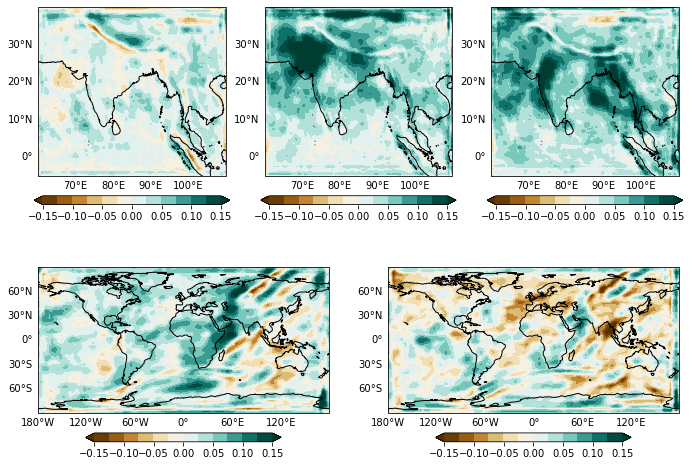

In [80]:
fig=plt.figure(figsize=(11.5,8))
clf=np.arange(-1.5,1.51,.25)*1e-1

plot(np.nanmean(saliency_map[:,:,:,0],0),lon,lat,clf=clf,cmap=cmap,sub=[2,3,1],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,1],0),lon,lat,clf=clf,cmap=cmap,sub=[2,3,2],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,2],0),lon,lat,clf=clf,cmap=cmap,sub=[2,3,3],fig=fig)

#clf=np.arange(-1.5,1.51,.25)*1e-1
plot(np.nanmean(saliency_map[:,:,:,5],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,3],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,6],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,4],fig=fig)

<GeoAxesSubplot:>

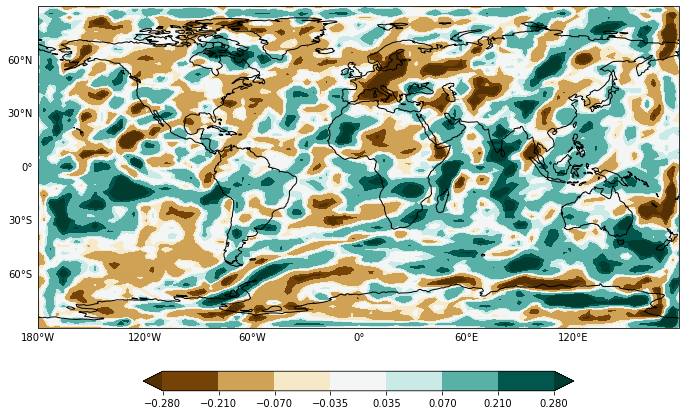

In [40]:
fig=plt.figure(figsize=(11.5,8))
clf=np.array([-.8,-.6,-.2,-.1,.1,.2,.6,.8])*3.5e-1
plot(np.nanmean(saliency_map[2:3,:,:,4],0),lon1,lat1,clf=clf,cmap=cmap,sub=[1,1,1],fig=fig,)

In [55]:
def wrap360(ds, lon='lon'):
    """
    wrap longitude coordinates to 0..360

    Parameters    ----------
    ds : Dataset
        object with longitude coordinates
    lon : string
        name of the longitude ('lon', 'longitude', ...)

    Returns
    -------
    wrapped : Dataset
        Another dataset array wrapped around.
    """

    # wrap -180..179 to 0..359
    ds.coords['lon'] = np.mod(ds['lon'], 360)

    # sort the data
    return ds.reindex({ 'lon' : np.sort(ds['lon'])})

<GeoAxesSubplot:>

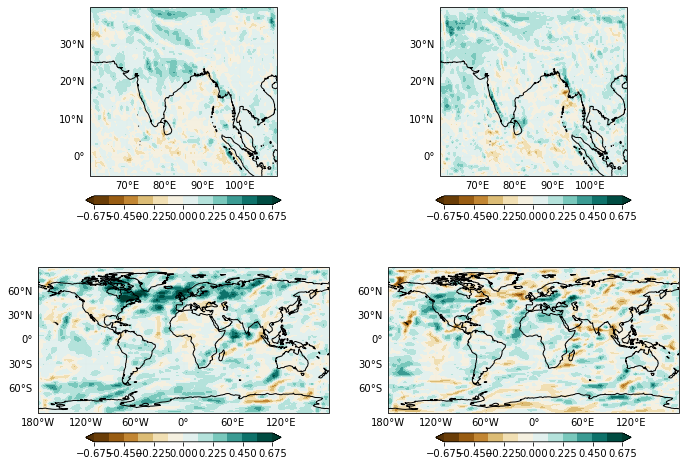

In [70]:
fig=plt.figure(figsize=(11.5,8))
clf=np.arange(-1.5,1.51,.25)*4.5e-1

plot((saliency_map[2,:,:,1]),lon,lat,clf=clf,cmap=cmap,sub=[2,2,1],fig=fig)
plot((saliency_map[2,:,:,2]),lon,lat,clf=clf,cmap=cmap,sub=[2,2,2],fig=fig)

#clf=np.arange(-1.5,1.51,.25)*2e-1
plot(saliency_map[2,:,:,3],lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,3],fig=fig)
plot(saliency_map[2,:,:,4],lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,4],fig=fig)

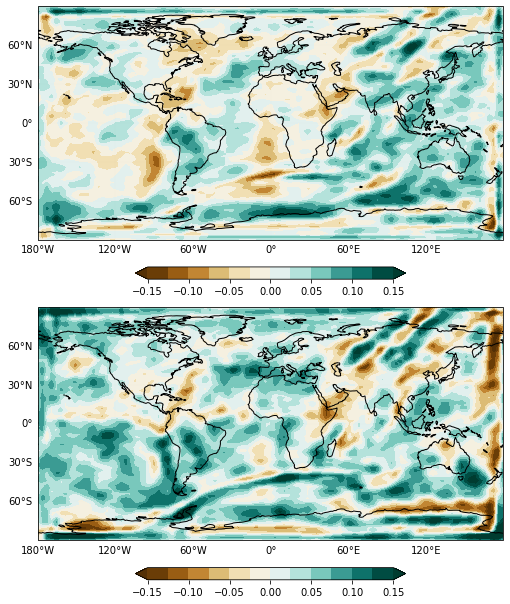

In [99]:
#clf=np.arange(-1.5,1.51,.25)*1e-1
fig=plt.figure(figsize=(11.5,8.5))
plot(np.nanmean(saliency_map[:,:,:,3],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,1,1],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,4],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,1,2],fig=fig)
plt.tight_layout()

In [146]:
sal=np.nanmean(saliency_map[:,:,:,6],0)

In [147]:
sal.shape

(91, 101)

In [103]:
ds = xr.Dataset({
    'sal': xr.DataArray(
                data   = sal,   # enter data here
                dims   = ['lat','lon'],
                coords = {'lon': lon1, 'lat': lat1},
                attrs  = {
                    '_FillValue': -999.9,
                    'units'     : 'W/m2'
                    }
                ),
            },
        attrs = {'example_attr': 'this is a global attribute'}
    )

In [104]:
ds

In [151]:
sal1=wrap360(ds,lon=ds.lon)

In [166]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

#fig = plt.figure(figsize=(11, 8.5))

# Create an axes with the PlateCarree projection

def plot(data,lon,lat,cmap='coolwarm',fig=[],nx=[],ny=[],sub=[1,1,1],clf=[],frac=.045):

    ax = fig.add_subplot(sub[0], sub[1], sub[2], projection=ccrs.PlateCarree(central_longitude=180))

    # Example usage of the axes
    ax.coastlines()  # Adds coastlines
    # try:
    #     ax.set_extent([nx[0], nx[1], ny[0], ny[1]]) # define the boundary
    # except:
    #     None
    ax.set_extent([60,250, -40, 40])
    try:
        cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both',levels=clf)
    except:
                cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both')

    plt.colorbar(cc,orientation='horizontal',  shrink=5,pad=0.1,fraction=frac)
    gl = ax.gridlines(draw_labels=True, linewidth=0.01)

    gl.xlabels_top = False  # Disable labels on the top
    gl.ylabels_right = False  # Disable labels on the right
    gl.xformatter = ccrs.cartopy.mpl.gridliner.LONGITUDE_FORMATTER
    gl.yformatter = ccrs.cartopy.mpl.gridliner.LATITUDE_FORMATTER

    return(ax)
#map5.contourf(lon,lat,Yp_norm_test[nn,:,:,1])


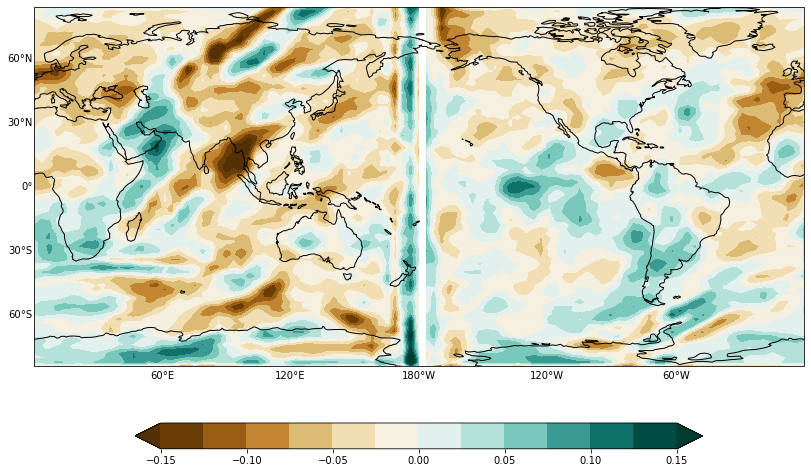

In [167]:
fig=plt.figure(figsize=(11,8.5))

ax=plot(sal,sal1.lon,lat1,clf=clf,cmap=cmap,sub=[1,1,1],fig=fig)

plt.tight_layout()

In [ ]:
# Create the subplots
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(14, 8),
                        subplot_kw={'projection': ccrs.PlateCarree()})

# Plot Pearson and Spearman Correlation between Precipitation and temperature on the subplots
# for i, ax in enumerate(axs.flat):
cs = ax.contourf(lon1, lat1,sal , 30, cmap='YlOrRd_r', extend='both', transform=ccrs.PlateCarree(), levels=np.arange(995,1006,1))
ax.add_feature(cf.COASTLINE)
ax.add_feature(cf.BORDERS, linewidth=1)
ax.add_feature(cf.OCEAN)
ax.add_feature(cf.LAKES)
ax.add_feature(cf.LAND)
ax.add_feature(cf.RIVERS)
ax.set_extent([70, 100, 0, 28])
bx = ax.gridlines(draw_labels=True, linewidth=0.2)
#ax.set_title(corr_title[i], fontsize=12, pad=10, y=1.04, loc="left")

# Add vertical colorbar to each subplot with a custom size
cbar = plt.colorbar(cs, ax=ax, orientation='vertical', pad=0.1, shrink=0.7)
cbar.ax.tick_params(labelsize=10)

# Adjust the spacing between subplots and display the plot
plt.tight_layout()

plt.show()